In [13]:
import os
import json
import time
import requests
import pandas as pd
from google.colab import files


csv_path = "/content/Stage_Classification_Importance.csv"
json_path = "/content/target_gene_ensg_mapping.json"
missing_path = "/content/unresolved_genes.txt"

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"Not found CSV: {csv_path}\n"
        "Define The Path Please."
    )


df = pd.read_csv(csv_path)

if "Gene" not in df.columns:
    raise ValueError(f"Thre is no 'Gene' column in csv: {list(df.columns)}")


genes = list(dict.fromkeys(
    df["Gene"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
))

print(f"total unique gene from csv: {len(genes)}")

session = requests.Session()
session.headers.update({
    "Accept": "application/json",
    "User-Agent": "Google-Colab-Gene-Mapping"
})

mapping = {}
unresolved = []


def get_ensembl_id(gene):
    """MyGene.info help us to find out Ensembl Id from human gene"""
    url = "https://mygene.info/v3/query"
    params = {
        "q": gene,
        "scopes": "symbol",
        "species": "human",
        "fields": "symbol,ensembl",
        "size": 10,
        "operator": "and"
    }

    for attempt in range(5 ):
        try:
            r = session.get(url, params=params, timeout=60)

            if r.status_code == 200:
                data = r.json()
                hits = data.get("hits", [])


                hits = sorted(
                    hits,
                    key=lambda x: str(x.get("symbol", "")).upper() != gene
                )

                for hit in hits:
                    ensembl = hit.get("ensembl")

                    if isinstance(ensembl, dict):
                        ensembl_id = ensembl.get("gene")
                        if isinstance(ensembl_id, str) and ensembl_id.startswith("ENSG"):
                            return ensembl_id

                    elif isinstance(ensembl, list):
                        for item in ensembl:
                            if isinstance(item, dict):
                                ensembl_id = item.get("gene")
                                if isinstance(ensembl_id, str) and ensembl_id.startswith("ENSG"):
                                    return ensembl_id

                return None

            if r.status_code in [429, 500, 502, 503, 504]:
                wait = min(2 ** attempt, 20)
                print(f"{gene}: HTTP {r.status_code}, retrying after {wait}s")
                time.sleep(wait)
                continue

            print(f"{gene}: HTTP {r.status_code}")
            return None

        except requests.RequestException as e:
            wait = min(2 ** attempt, 20)
            print(f"{gene}: connection error, retrying after {wait}s")
            time.sleep(wait)

    return None



for i, gene in enumerate(genes, start=1):
    print(f"[{i}/{len(genes)}] {gene}")

    ensembl_id = get_ensembl_id(gene)

    if ensembl_id:
        mapping[gene] = ensembl_id
    else:
        unresolved.append(gene)
        print(f"  ID No found: {gene}")

    time.sleep(0.2)

# save as JSON format
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(mapping, f, indent=4, ensure_ascii=False)
    f.write("\n")


with open(missing_path, "w", encoding="utf-8") as f:
    f.write("\n".join(unresolved))
    if unresolved:
        f.write("\n")

print("\nCompleted")
print(f"total gene: {len(genes)}")
print(f"Mapping found: {len(mapping)}")
print(f"Mapping did not find: {len(unresolved)}")
print(f"JSON created: {json_path}")

# JSON download



total unique gene from csv: 72
[1/72] COL1A1
[2/72] DKC1
[3/72] ETV4
[4/72] GTF2IRD1
[5/72] TIMP1
[6/72] NR3C2
[7/72] HILPDA
[8/72] UGP2
[9/72] NFE2L3
[10/72] PPM1H
[11/72] INHBA
[12/72] NDRG2
[13/72] DNAJC2
[14/72] H3.3B
[15/72] CA2
[16/72] PDK4
[17/72] SND1
[18/72] PJA2
[19/72] S100A11
[20/72] ZG16
[21/72] OGFR
[22/72] OSBPL3
[23/72] ACTR5
[24/72] FOXF2
[25/72] AMPD2
[26/72] PTGER4
[27/72] PUS7
[28/72] COL4A5
[29/72] PGCKA1
[30/72] PLXNA1
[31/72] YEATS2
[32/72] PPP2CB
[33/72] CHPF
[34/72] RAB27A
[35/72] RAE1
[36/72] EFNA3
[37/72] KLF4
[38/72] ADH5
[39/72] HIGD1A
[40/72] AKAP7
[41/72] MSH5
[42/72] TAF1D
[43/72] CDH3
[44/72] MTUS1
[45/72] SOX4
[46/72] PAQR4
[47/72] RHBDF2
[48/72] ARFGAP1
[49/72] TNFSF10
[50/72] PDCD4
[51/72] SLC4A4
[52/72] NDUFA6
[53/72] CA4
[54/72] CFD
[55/72] NEDD4L
[56/72] PFDN4
[57/72] BBLN
[58/72] SLC12A8
[59/72] TPD52L2
[60/72] PTP4A1
[61/72] MRPL57
[62/72] CAVIN2
[63/72] GSTM2
[64/72] ABHD3
[65/72] TCOF1
[66/72] PAFAH1B1
[67/72] FAS
[68/72] RBCK1
[69/72] CALM1
[

total target gene: 72
['COL1A1', 'DKC1', 'ETV4', 'GTF2IRD1', 'TIMP1', 'NR3C2', 'HILPDA', 'UGP2', 'NFE2L3', 'PPM1H', 'INHBA', 'NDRG2', 'DNAJC2', 'H3.3B', 'CA2', 'PDK4', 'SND1', 'PJA2', 'S100A11', 'ZG16', 'OGFR', 'OSBPL3', 'ACTR5', 'FOXF2', 'AMPD2', 'PTGER4', 'PUS7', 'COL4A5', 'PGCKA1', 'PLXNA1', 'YEATS2', 'PPP2CB', 'CHPF', 'RAB27A', 'RAE1', 'EFNA3', 'KLF4', 'ADH5', 'HIGD1A', 'AKAP7', 'MSH5', 'TAF1D', 'CDH3', 'MTUS1', 'SOX4', 'PAQR4', 'RHBDF2', 'ARFGAP1', 'TNFSF10', 'PDCD4', 'SLC4A4', 'NDUFA6', 'CA4', 'CFD', 'NEDD4L', 'PFDN4', 'BBLN', 'SLC12A8', 'TPD52L2', 'PTP4A1', 'MRPL57', 'CAVIN2', 'GSTM2', 'ABHD3', 'TCOF1', 'PAFAH1B1', 'FAS', 'RBCK1', 'CALM1', 'DGKZ', 'CDK5RAP1', 'TRAK2']

Tissue
AUC: 0.8786982248520709
Accuracy: 0.8076923076923077
Sensitivity: 0.6923076923076923
Specificity: 0.9230769230769231
F1: 0.782608695652174
  AUC 95% CI:         [0.702, 1.000]
  Accuracy 95% CI:    [0.654, 0.962]
  Sensitivity 95% CI: [0.417, 0.923]
  Precision 95% CI:   [0.667, 1.000]
  F1 95% CI:         

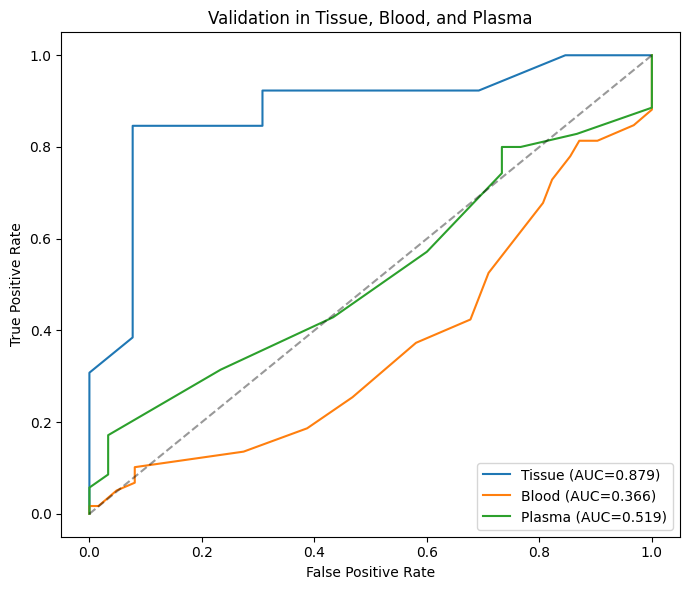

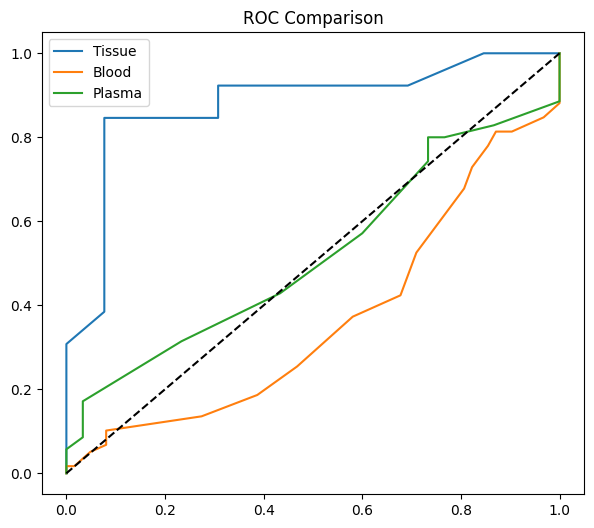

In [14]:
import pandas as pd
import numpy as np
import re
import gzip
import json
import warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import shap




def bootstrap_ci_binary(y_true, y_prob, n_boot=2000, seed=123):
    rng = np.random.RandomState(seed)
    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    n = len(y_true)
    aucs, accs, sens, precs, f1s = [], [], [], [], []
    for _ in range(n_boot):
        idx = rng.choice(n, size=n, replace=True)
        yt, yp = y_true[idx], y_prob[idx]
        if len(np.unique(yt)) < 2:
            continue
        pred = (yp >= 0.5).astype(int)
        aucs.append(roc_auc_score(yt, yp))
        accs.append(accuracy_score(yt, pred))
        sens.append(recall_score(yt, pred, zero_division=0))
        precs.append(precision_score(yt, pred, zero_division=0))
        f1s.append(f1_score(yt, pred, zero_division=0))
    def ci(x): return np.percentile(x, [2.5, 97.5])
    return {"AUC_CI": ci(aucs), "Accuracy_CI": ci(accs),
            "Sensitivity_CI": ci(sens), "Precision_CI": ci(precs), "F1_CI": ci(f1s)}




def clopper_pearson(k, n, alpha=0.05):
    """Exact (Clopper-Pearson) 95% CI for a proportion k/n."""
    lo = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - alpha / 2, k + 1, n - k)
    return float(lo), float(hi)



csv_path = "/content/Stage_Classification_Importance.csv"


if not os.path.exists(csv_path):
    raise FileNotFoundError(f"CSV did not find: {csv_path}")

# CSV read
df = pd.read_csv(csv_path)


if "Gene" not in df.columns:
    raise ValueError(
        f"CSV file has no 'Gene' column. Columns: {list(df.columns)}"
    )


# Duplicate gene removed
target_genes = list(dict.fromkeys(
    df["Gene"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
))

print(f"total target gene: {len(target_genes)}")
print(target_genes)



def load_gse41258():
    file_path = '/content/GSE41258_series_matrix.txt.gz'
    titles, chars = [], []

    with gzip.open(file_path, 'rt') as f:
        for line in f:
            if line.startswith('!Sample_title'):
                titles = [t.strip('"') for t in line.split('\t')[1:]]
            elif line.startswith('!Sample_characteristics_ch1'):
                chars.append([t.strip('"') for t in line.split('\t')[1:]])

    df = pd.read_csv(file_path, sep='\t', comment='!', index_col=0)

    chars_df = pd.DataFrame(chars).T.fillna('')
    combined = chars_df.apply(lambda x: ' '.join(x).lower(), axis=1).tolist()
    texts = [f"{t.lower()} {c}" for t, c in zip(titles, combined)]

    labels = []
    for txt in texts:
        if re.search(r"(metastasis|primary|carcinoma|crc)", txt):
            labels.append(1)
        elif re.search(r"(normal|control|healthy)", txt):
            labels.append(0)
        else:
            labels.append(-1)

    idx = [i for i,x in enumerate(labels) if x!=-1]
    return df.iloc[:,idx], [labels[i] for i in idx]

def load_gse110223():
    titles=[]
    with gzip.open('/content/GSE110223_series_matrix.txt.gz','rt') as f:
        for line in f:
            if line.startswith('!Sample_title'):
                titles=[t.strip('"') for t in line.split('\t')[1:]]
                break
    df=pd.read_csv('/content/GSE110223_series_matrix.txt.gz',sep='\t',comment='!',index_col=0)
    labels=[1 if 'cancer' in t.lower() else 0 for t in titles]
    return df,labels

def load_gse164191():
    df=pd.read_csv('/content/GSE164191_series_matrix.txt.gz',sep='\t',comment='!',index_col=0)
    return df,[0]*62+[1]*59

def load_gse142987():
    df=pd.read_csv('/content/GSE142987_sample_count_matrix.txt.gz',sep='\t',index_col=0)
    labels=[1 if c.startswith('L') else 0 for c in df.columns]
    return df,labels

def load_mappings():
    gpl=pd.read_csv('/content/GPL570-55999(2).txt',sep='\t',comment='#',low_memory=False)
    gpl_map={r['ID']:str(r['Gene Symbol']).split(' /// ')[0] for _,r in gpl.iterrows()}
    with open('/content/target_gene_ensg_mapping.json') as f:
        ensg=json.load(f)
    return gpl_map,{v:k for k,v in ensg.items()}


# PREPROCESS (LEAKAGE FIXED)

def preprocess(df, mapping, scaler=None, fit=False, is_ensg=False):
    if is_ensg:
        df.index=[i.split('.')[0] for i in df.index]

    df['Symbol']=df.index.map(mapping)
    df=df.dropna(subset=['Symbol'])

    X=df.groupby('Symbol').mean().T

    for g in target_genes:
        if g not in X.columns:
            X[g]=0
    X=X[target_genes]

    if X.max().max()>50:
        X=np.log2(X+1)

    if fit:
        scaler=StandardScaler()
        X=scaler.fit_transform(X)
    else:
        X=scaler.transform(X)

    return pd.DataFrame(X,columns=target_genes,index=X.index if isinstance(X,pd.DataFrame) else None), scaler


def evaluate(y, probs, name):
    pred=(probs>=0.5).astype(int)

    tn,fp,fn,tp=confusion_matrix(y,pred).ravel()

    print(f"\n{name}")
    print("AUC:",roc_auc_score(y,probs))
    print("Accuracy:",accuracy_score(y,pred))
    print("Sensitivity:",tp/(tp+fn))
    print("Specificity:",tn/(tn+fp))
    print("F1:",f1_score(y,pred))

    #  bootstrap 95% CI
    ci_result = bootstrap_ci_binary(y, probs)
    print(f"  AUC 95% CI:         [{ci_result['AUC_CI'][0]:.3f}, {ci_result['AUC_CI'][1]:.3f}]")
    print(f"  Accuracy 95% CI:    [{ci_result['Accuracy_CI'][0]:.3f}, {ci_result['Accuracy_CI'][1]:.3f}]")
    print(f"  Sensitivity 95% CI: [{ci_result['Sensitivity_CI'][0]:.3f}, {ci_result['Sensitivity_CI'][1]:.3f}]")
    print(f"  Precision 95% CI:   [{ci_result['Precision_CI'][0]:.3f}, {ci_result['Precision_CI'][1]:.3f}]")
    print(f"  F1 95% CI:          [{ci_result['F1_CI'][0]:.3f}, {ci_result['F1_CI'][1]:.3f}]")
    sens_lo, sens_hi = clopper_pearson(tp, tp + fn)
    spec_lo, spec_hi = clopper_pearson(tn, tn + fp)
    print(f"  Sensitivity exact 95% CI ({tp}/{tp+fn}): [{sens_lo:.3f}, {sens_hi:.3f}]")
    print(f"  Specificity exact 95% CI ({tn}/{tn+fp}): [{spec_lo:.3f}, {spec_hi:.3f}]")

# RUN PIPELINE

gpl_map,ensg_map=load_mappings()

# TRAIN
df_train,y_train=load_gse41258()
X_train,scaler=preprocess(df_train,gpl_map,fit=True)

model=RandomForestClassifier(n_estimators=100,random_state=42)
model.fit(X_train,y_train)

# TEST
datasets=[]
for name,loader,args in [
    ("Tissue",load_gse110223,(gpl_map,False)),
    ("Blood",load_gse164191,(gpl_map,False)),
    ("Plasma",load_gse142987,(ensg_map,True))
]:
    df,y=loader()
    X,_=preprocess(df,args[0],scaler=scaler,is_ensg=args[1])
    p=model.predict_proba(X)[:,1]
    evaluate(y,p,name)
    datasets.append((name,y,p,X))

# Figure
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(7,6))
for name, y, p, _ in datasets:   # reuse the same datasets list from your loop
    fpr, tpr, _ = roc_curve(y, p)
    auc_val = roc_auc_score(y, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})")
plt.plot([0,1],[0,1],'k--', alpha=0.4)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Validation in Tissue, Blood, and Plasma")
plt.legend()
plt.tight_layout()
plt.savefig("Figure7_Tissue_Blood_Plasma_ROC.png", dpi=300)
plt.show()

# Figure


# ROC PLOT
plt.figure(figsize=(7,6))
for name,y,p,_ in datasets:
    fpr,tpr,_=roc_curve(y,p)
    plt.plot(fpr,tpr,label=name)
plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("ROC Comparison")
plt.savefig("ROC.png",dpi=300)
plt.show()






In [15]:
gpl_map, ensg_map = load_mappings()

def count_missing(df, mapping, is_ensg=False):
    d = df.copy()
    if is_ensg:
        d.index = [i.split('.')[0] for i in d.index]
    syms = set(d.index.map(mapping).dropna())
    miss = [g for g in target_genes if g not in syms]
    return len(miss), miss

for name, loader, m, e in [
    ("Tissue GSE110223", load_gse110223, gpl_map, False),
    ("Blood GSE164191",  load_gse164191,  gpl_map, False),
    ("Plasma GSE142987", load_gse142987,  ensg_map, True),
]:
    d, _ = loader()
    n, miss = count_missing(d, m, e)
    print(f"{name}: {n} of {len(target_genes)} target genes missing", miss[:10])

Tissue GSE110223: 5 of 72 target genes missing ['H3.3B', 'PGCKA1', 'PDCD4', 'BBLN', 'CAVIN2']
Blood GSE164191: 4 of 72 target genes missing ['H3.3B', 'PGCKA1', 'BBLN', 'CAVIN2']
Plasma GSE142987: 4 of 72 target genes missing ['H3.3B', 'MSH5', 'NDUFA6', 'CFD']


Loading GSE164191 (Blood Data)...
Samples: 121, Cancer: 59, Healthy: 62
Processing Fold 1...
Processing Fold 2...
Processing Fold 3...
Processing Fold 4...
Processing Fold 5...


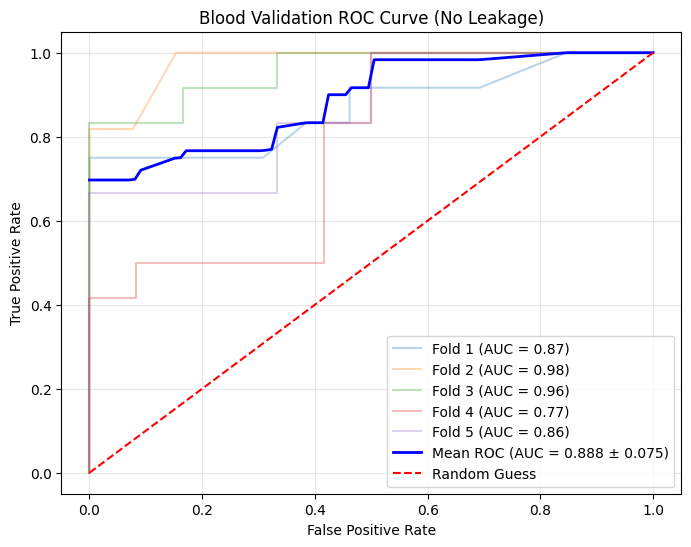


      FINAL RESULTS
AUC:       0.888 ± 0.075
Accuracy:  0.818
Precision: 0.903
Recall:    0.744
F1-score:  0.800

===== POOLED OUT-OF-FOLD 95% CI =====
AUC 95% CI:         [0.823, 0.940]
Accuracy 95% CI:    [0.744, 0.884]
Sensitivity 95% CI: [0.650, 0.868]
Precision 95% CI:   [0.750, 0.935]
F1 95% CI:          [0.714, 0.876]
Pooled OOF AUC: 0.887

 Validated gene list saved as 'Validated_Genes_Blood.csv'

Top 10 Most Consistent Genes in Blood:
       Probe_ID          Gene_Symbol  Selection_Frequency
1    1557166_at                PDCD4                    5
3    1558654_at      AK024134, PPM1H                    5
5   200622_x_at  CALM1, CALM2, CALM3                    5
4    1562321_at                 PDK4                    5
6   200623_s_at  CALM1, CALM2, CALM3                    5
7   200653_s_at  CALM1, CALM2, CALM3                    5
10  200815_s_at             PAFAH1B1                    5
8     200660_at              S100A11                    5
38  209627_s_at              

In [16]:
import pandas as pd
import numpy as np
import os
import gzip
from scipy import stats
from collections import Counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import warnings





def bootstrap_ci_binary(y_true, y_prob, n_boot=2000, seed=123):
    rng = np.random.RandomState(seed)
    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    n = len(y_true)
    aucs, accs, sens, precs, f1s = [], [], [], [], []
    for _ in range(n_boot):
        idx = rng.choice(n, size=n, replace=True)
        yt, yp = y_true[idx], y_prob[idx]
        if len(np.unique(yt)) < 2:
            continue
        pred = (yp >= 0.5).astype(int)
        aucs.append(roc_auc_score(yt, yp))
        accs.append(accuracy_score(yt, pred))
        sens.append(recall_score(yt, pred, zero_division=0))
        precs.append(precision_score(yt, pred, zero_division=0))
        f1s.append(f1_score(yt, pred, zero_division=0))
    def ci(x): return np.percentile(x, [2.5, 97.5])
    return {"AUC_CI": ci(aucs), "Accuracy_CI": ci(accs),
            "Sensitivity_CI": ci(sens), "Precision_CI": ci(precs), "F1_CI": ci(f1s)}







warnings.filterwarnings("ignore")


def load_data():
    print("Loading GSE164191 (Blood Data)...")
    file_path = '/content/GSE164191_series_matrix.txt.gz'
    if not os.path.exists(file_path):
        raise FileNotFoundError("Dataset not found! Please upload GSE164191 file.")

    df = pd.read_csv(file_path, sep='\t', comment='!', index_col=0)

    # Label extraction from titles
    with gzip.open(file_path, 'rt') as f:
        for line in f:
            if line.startswith('!Sample_title'):
                titles = line.strip().split('\t')[1:]
                break

    y = np.array([1 if any(x in t.lower() for x in ['crc', 'cancer', 'colorectal']) else 0 for t in titles])
    print(f"Samples: {len(y)}, Cancer: {sum(y)}, Healthy: {len(y)-sum(y)}")
    return df, y


def get_gene_mapping():
    file_path = '/content/GPL570-55999(2).txt'
    if not os.path.exists(file_path):
        raise FileNotFoundError("GPL570 mapping file not found!")

    gpl = pd.read_csv(file_path, sep='\t', comment='#', low_memory=False)
    # Mapping Probe ID to a list of symbols
    mapping = {str(row['ID']): str(row['Gene Symbol']).split(' /// ') for _, row in gpl.iterrows()}
    return mapping




# FEATURE SELECTION

def select_features(X_train, y_train, mapping):
    selected = []
    cancer_idx = np.where(y_train == 1)[0]
    healthy_idx = np.where(y_train == 0)[0]

    for probe in X_train.index:
        symbols = mapping.get(probe, [])
        # Check if any symbol of this probe is in our target genes
        if not any(s in target_genes for s in symbols):
            continue

        c = X_train.loc[probe].iloc[cancer_idx].values.astype(float)
        h = X_train.loc[probe].iloc[healthy_idx].values.astype(float)

        if len(c) < 2 or len(h) < 2:
            continue

        fc = np.mean(c) / (np.mean(h) + 1e-6)
        p = stats.ttest_ind(c, h, equal_var=False).pvalue

        # T-test and Fold Change filter
        if (fc > 1.1 or fc < 0.9) and p < 0.05:
            selected.append(probe)
    return selected

# BOOTSTRAP STABILITY OF BLOOD FEATURE SELECTION

def bootstrap_feature_stability(X, y, mapping, n_boot=50, seed=123):
    rng = np.random.RandomState(seed)
    y = np.array(y)
    idx_cancer = np.where(y == 1)[0]
    idx_healthy = np.where(y == 0)[0]

    probe_hits = Counter()

    for b in range(n_boot):
        boot_idx = np.concatenate([
            rng.choice(idx_cancer, size=len(idx_cancer), replace=True),
            rng.choice(idx_healthy, size=len(idx_healthy), replace=True)
        ])
        X_boot = X.iloc[:, boot_idx]
        y_boot = y[boot_idx]

        selected = select_features(X_boot, y_boot, mapping)
        probe_hits.update(selected)

        if (b + 1) % 10 == 0:
            print(f"  bootstrap {b+1}/{n_boot} done")

    rows = []
    for p_id, freq in probe_hits.items():
        rows.append({
            "Probe_ID": p_id,
            "Gene_Symbol": ", ".join(mapping.get(p_id, ["N/A"])),
            "Times_Selected": freq,
            "Selection_Rate": freq / n_boot
        })

    freq_df = pd.DataFrame(rows).sort_values("Selection_Rate", ascending=False)
    freq_df.to_csv("Blood_Panel_Bootstrap_Stability.csv", index=False)

    print(f"\n BLOOD-PANEL BOOTSTRAP STABILITY ({n_boot} resamples):")
    print(f"Mean selection rate: {freq_df['Selection_Rate'].mean()*100:.1f}%")
    print(f"Probes selected in ≥80% of bootstraps: {(freq_df['Selection_Rate']>=0.8).sum()} / {len(freq_df)}")
    print(freq_df.head(15).to_string())

    return freq_df


# MAIN PIPELINE

def run_pipeline(X, y, mapping):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    tprs, aucs, accs, precs, recs, f1s = [], [], [], [], [], []
    oof_true, oof_prob = [], []
    all_selected_probes = []
    mean_fpr = np.linspace(0, 1, 100)

    plt.figure(figsize=(8, 6))

    for fold, (train_idx, test_idx) in enumerate(cv.split(X.T, y)):
        print(f"Processing Fold {fold+1}...")

        X_train, X_test = X.iloc[:, train_idx], X.iloc[:, test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        #  Feature selection only on training data
        selected = select_features(X_train, y_train, mapping)
        all_selected_probes.extend(selected)

        if not selected:
            continue

        model = RandomForestClassifier(n_estimators=100, random_state=42)
        model.fit(X_train.loc[selected].T, y_train)

        probs = model.predict_proba(X_test.loc[selected].T)[:, 1]
        oof_true.extend(y_test)
        oof_prob.extend(probs)
        fpr, tpr, _ = roc_curve(y_test, probs)

        tprs.append(np.interp(mean_fpr, fpr, tpr))
        aucs.append(auc(fpr, tpr))

        plt.plot(fpr, tpr, alpha=0.3, label=f'Fold {fold+1} (AUC = {auc(fpr, tpr):.2f})')

        preds = model.predict(X_test.loc[selected].T)
        accs.append(accuracy_score(y_test, preds))
        precs.append(precision_score(y_test, preds))
        recs.append(recall_score(y_test, preds))
        f1s.append(f1_score(y_test, preds))



    # Plotting Mean ROC
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(aucs)

    plt.plot(mean_fpr, mean_tpr, color='blue', label=f'Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})', lw=2)
    plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Guess')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Blood Validation ROC Curve (No Leakage)')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.savefig("Final_Blood_ROC.png", dpi=300)
    plt.show()

    # Metrics Output
    print("\n" + "="*30)
    print("      FINAL RESULTS")
    print("="*30)
    print(f"AUC:       {np.mean(aucs):.3f} ± {std_auc:.3f}")
    print(f"Accuracy:  {np.mean(accs):.3f}")
    print(f"Precision: {np.mean(precs):.3f}")
    print(f"Recall:    {np.mean(recs):.3f}")
    print(f"F1-score:  {np.mean(f1s):.3f}")

    # pooled out-of-fold 95% CI (proper generalization CI)
    ci_blood = bootstrap_ci_binary(oof_true, oof_prob)
    print("\n===== POOLED OUT-OF-FOLD 95% CI =====")
    print(f"AUC 95% CI:         [{ci_blood['AUC_CI'][0]:.3f}, {ci_blood['AUC_CI'][1]:.3f}]")
    print(f"Accuracy 95% CI:    [{ci_blood['Accuracy_CI'][0]:.3f}, {ci_blood['Accuracy_CI'][1]:.3f}]")
    print(f"Sensitivity 95% CI: [{ci_blood['Sensitivity_CI'][0]:.3f}, {ci_blood['Sensitivity_CI'][1]:.3f}]")
    print(f"Precision 95% CI:   [{ci_blood['Precision_CI'][0]:.3f}, {ci_blood['Precision_CI'][1]:.3f}]")
    print(f"F1 95% CI:          [{ci_blood['F1_CI'][0]:.3f}, {ci_blood['F1_CI'][1]:.3f}]")

    print(f"Pooled OOF AUC: {roc_auc_score(oof_true, oof_prob):.3f}")



    #  Save All Genes
    counts = Counter(all_selected_probes)
    gene_summary = []
    for p_id, freq in counts.items():
        gene_summary.append({
            "Probe_ID": p_id,
            "Gene_Symbol": ", ".join(mapping.get(p_id, ["N/A"])),
            "Selection_Frequency": freq
        })

    df_genes = pd.DataFrame(gene_summary).sort_values(by="Selection_Frequency", ascending=False)
    df_genes.to_csv("Validated_Genes_Blood.csv", index=False)

    print("\n Validated gene list saved as 'Validated_Genes_Blood.csv'")
    print("\nTop 10 Most Consistent Genes in Blood:")
    print(df_genes.head(10))



if __name__ == "__main__":
    df, y = load_data()
    mapping = get_gene_mapping()
    run_pipeline(df, y, mapping)

    # bootstrap stability check
    blood_stability_df = bootstrap_feature_stability(df, y, mapping, n_boot=50)


Loading GSE164191 (Blood Data)...
Samples: 121, Cancer: 59, Healthy: 62
 Final locked blood panel: 81 probes
GSE10715 — Samples: 30, CRC: 19, Normal: 11
Probes missing in GSE10715: 0 of 81

 GSE10715 EXTERNAL VALIDATION RESULTS
AUC:         0.885
Accuracy:    0.667
Sensitivity: 1.000
Specificity: 0.091
Precision:   0.655
F1-score:    0.792

 95% Bootstrap CI 
AUC 95% CI:         [0.728, 0.998]
Accuracy 95% CI:    [0.500, 0.833]
Sensitivity 95% CI: [1.000, 1.000]


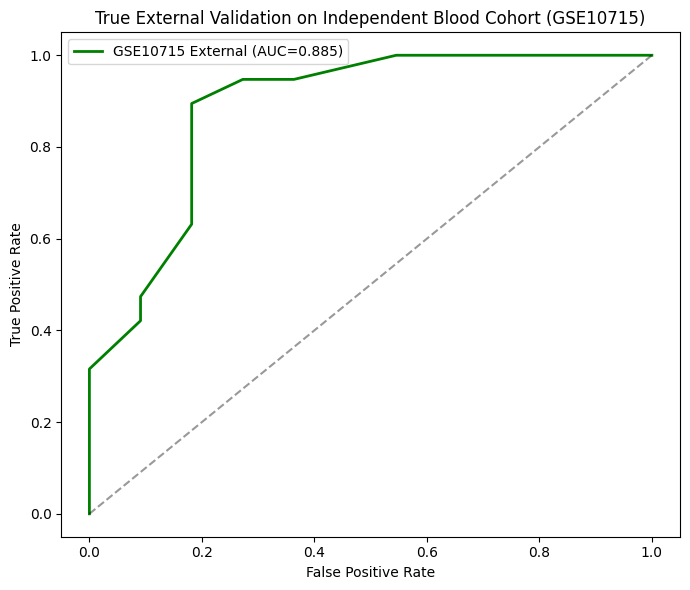

In [17]:

# EXTERNAL VALIDATION ON A SECOND, INDEPENDENT BLOOD COHORT (GSE10715)


import pandas as pd
import numpy as np
import gzip
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt


# STEP 1: Train ONE final, locked blood model on the FULL GSE164191 dataset

#existing loader
df, y = load_data()
mapping = get_gene_mapping()

final_selected_probes = select_features(df, y, mapping)
print(f" Final locked blood panel: {len(final_selected_probes)} probes")

final_model = RandomForestClassifier(n_estimators=100, random_state=42)
final_model.fit(df.loc[final_selected_probes].T, y)

# Save this as the frozen, externally-validated model
import joblib
joblib.dump(final_model, "Final_Locked_Blood_Model.pkl")
pd.Series(final_selected_probes).to_csv("Final_Locked_Blood_Probes.csv", index=False)


#  Loading GSE10715

def load_gse10715():
    file_path = '/content/GSE10715_series_matrix.txt.gz'
    df_ext = pd.read_csv(file_path, sep='\t', comment='!', index_col=0)

    with gzip.open(file_path, 'rt') as f:
        chars = None
        for line in f:
            if line.startswith('!Sample_characteristics_ch1'):
                chars = line.strip().split('\t')[1:]
                break

    # "Blood: Normal" -> 0, "Blood: CRC stage Duke A, B" / "Duke C, D" -> 1
    y_ext = np.array([0 if 'normal' in c.lower() else 1 for c in chars])
    print(f"GSE10715 — Samples: {len(y_ext)}, CRC: {sum(y_ext)}, Normal: {len(y_ext)-sum(y_ext)}")
    return df_ext, y_ext

X_ext, y_ext = load_gse10715()


# Align GSE10715 probes to the locked model's feature set


missing_probes = [p for p in final_selected_probes if p not in X_ext.index]
print(f"Probes missing in GSE10715: {len(missing_probes)} of {len(final_selected_probes)}")

X_ext_aligned = pd.DataFrame(index=final_selected_probes, columns=X_ext.columns, dtype=float)
for p in final_selected_probes:
    if p in X_ext.index:
        X_ext_aligned.loc[p] = X_ext.loc[p]
    else:
        # impute missing probes with the TRAINING (GSE164191) mean — no leakage from GSE10715
        X_ext_aligned.loc[p] = df.loc[p].mean()


# Predict and evaluate on GSE10715

probs_ext = final_model.predict_proba(X_ext_aligned.T)[:, 1]
preds_ext = (probs_ext >= 0.5).astype(int)

auc_ext = roc_auc_score(y_ext, probs_ext)
acc_ext = accuracy_score(y_ext, preds_ext)
sens_ext = recall_score(y_ext, preds_ext)
prec_ext = precision_score(y_ext, preds_ext, zero_division=0)
f1_ext = f1_score(y_ext, preds_ext, zero_division=0)
tn, fp, fn, tp = confusion_matrix(y_ext, preds_ext).ravel()
spec_ext = tn / (tn + fp)

print("\n GSE10715 EXTERNAL VALIDATION RESULTS")
print(f"AUC:         {auc_ext:.3f}")
print(f"Accuracy:    {acc_ext:.3f}")
print(f"Sensitivity: {sens_ext:.3f}")
print(f"Specificity: {spec_ext:.3f}")
print(f"Precision:   {prec_ext:.3f}")
print(f"F1-score:    {f1_ext:.3f}")

# Bootstrap 95% CI
ci_ext_blood = bootstrap_ci_binary(y_ext, probs_ext, n_boot=2000)
print("\n 95% Bootstrap CI ")
print(f"AUC 95% CI:         [{ci_ext_blood['AUC_CI'][0]:.3f}, {ci_ext_blood['AUC_CI'][1]:.3f}]")
print(f"Accuracy 95% CI:    [{ci_ext_blood['Accuracy_CI'][0]:.3f}, {ci_ext_blood['Accuracy_CI'][1]:.3f}]")
print(f"Sensitivity 95% CI: [{ci_ext_blood['Sensitivity_CI'][0]:.3f}, {ci_ext_blood['Sensitivity_CI'][1]:.3f}]")

#ROC figure
fpr_ext, tpr_ext, _ = roc_curve(y_ext, probs_ext)
plt.figure(figsize=(7,6))
plt.plot(fpr_ext, tpr_ext, color='green', lw=2, label=f"GSE10715 External (AUC={auc_ext:.3f})")
plt.plot([0,1],[0,1],'k--', alpha=0.4)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("True External Validation on Independent Blood Cohort (GSE10715)")
plt.legend()
plt.tight_layout()
plt.savefig("Figure_GSE10715_External_Validation_ROC.png", dpi=300)
plt.show()

pd.DataFrame([{
    "Dataset": "GSE10715", "N": len(y_ext), "N_CRC": int(sum(y_ext)), "N_Normal": int(len(y_ext)-sum(y_ext)),
    "AUC": auc_ext, "Accuracy": acc_ext, "Sensitivity": sens_ext, "Specificity": spec_ext,
    "Precision": prec_ext, "F1": f1_ext
}]).to_csv("GSE10715_External_Validation_Results.csv", index=False)

In [18]:


# BATCH-CORRECTION ATTEMPT: PER-STUDY Z-SCORE STANDARDIZATION
# (each dataset's OWN mean/SD, no labels involved,




#Re-train the final locked model using Z-SCORED GSE164191 values


# Compute per-probe mean/SD from GSE164191 (train) — same 81 probes as before
train_means = df.loc[final_selected_probes].mean(axis=1)
train_stds  = df.loc[final_selected_probes].std(axis=1)

X_train_z = df.loc[final_selected_probes].sub(train_means, axis=0).div(train_stds, axis=0)

final_model_z = RandomForestClassifier(n_estimators=100, random_state=42)
final_model_z.fit(X_train_z.T, y)

print(" Re-trained final model on z-scored GSE164191 values")


#Z-score GSE10715 using ITS OWN mean/SD (per-study standardization —
# no GSE164191 statistics used here, no label information used either)


ext_means = X_ext_aligned.mean(axis=1)
ext_stds  = X_ext_aligned.std(axis=1)

X_ext_z = X_ext_aligned.sub(ext_means, axis=0).div(ext_stds, axis=0)


# STEP 3: Predict and evaluate again, with correction applied


probs_ext_bc = final_model_z.predict_proba(X_ext_z.T)[:, 1]
preds_ext_bc = (probs_ext_bc >= 0.5).astype(int)

auc_bc  = roc_auc_score(y_ext, probs_ext_bc)
acc_bc  = accuracy_score(y_ext, preds_ext_bc)
sens_bc = recall_score(y_ext, preds_ext_bc)
prec_bc = precision_score(y_ext, preds_ext_bc, zero_division=0)
f1_bc   = f1_score(y_ext, preds_ext_bc, zero_division=0)
tn, fp, fn, tp = confusion_matrix(y_ext, preds_ext_bc).ravel()
spec_bc = tn / (tn + fp)

print("\n GSE10715 EXTERNAL VALIDATION — AFTER PER-STUDY Z-SCORE CORRECTION =====")
print(f"AUC:         {auc_bc:.3f}")
print(f"Accuracy:    {acc_bc:.3f}")
print(f"Sensitivity: {sens_bc:.3f}")
print(f"Specificity: {spec_bc:.3f}")
print(f"Precision:   {prec_bc:.3f}")
print(f"F1-score:    {f1_bc:.3f}")

ci_bc = bootstrap_ci_binary(y_ext, probs_ext_bc, n_boot=2000)
print("\n 95% Bootstrap CI (after correction) ")
print(f"AUC 95% CI:         [{ci_bc['AUC_CI'][0]:.3f}, {ci_bc['AUC_CI'][1]:.3f}]")
print(f"Accuracy 95% CI:    [{ci_bc['Accuracy_CI'][0]:.3f}, {ci_bc['Accuracy_CI'][1]:.3f}]")
print(f"Sensitivity 95% CI: [{ci_bc['Sensitivity_CI'][0]:.3f}, {ci_bc['Sensitivity_CI'][1]:.3f}]")


# side-by-side comparison
comparison_bc = pd.DataFrame({
    "Metric": ["AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "F1"],
    "Before_Correction": [auc_ext, acc_ext, sens_ext, spec_ext, prec_ext, f1_ext],
    "After_ZScore_Correction": [auc_bc, acc_bc, sens_bc, spec_bc, prec_bc, f1_bc]
})
print("\n", comparison_bc.to_string(index=False))
comparison_bc.to_csv("GSE10715_Batch_Correction_Comparison.csv", index=False)

 Re-trained final model on z-scored GSE164191 values

 GSE10715 EXTERNAL VALIDATION — AFTER PER-STUDY Z-SCORE CORRECTION =====
AUC:         0.840
Accuracy:    0.700
Sensitivity: 0.684
Specificity: 0.727
Precision:   0.812
F1-score:    0.743

 95% Bootstrap CI (after correction) 
AUC 95% CI:         [0.679, 0.964]
Accuracy 95% CI:    [0.533, 0.834]
Sensitivity 95% CI: [0.467, 0.889]

      Metric  Before_Correction  After_ZScore_Correction
        AUC           0.885167                 0.839713
   Accuracy           0.666667                 0.700000
Sensitivity           1.000000                 0.684211
Specificity           0.090909                 0.727273
  Precision           0.655172                 0.812500
         F1           0.791667                 0.742857


In [19]:


# More about EXTERNAL VALIDATION REPORT FOR


import numpy as np
import pandas as pd

from scipy.stats import beta
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    confusion_matrix
)
from sklearn.linear_model import LogisticRegression



# Exact 95% confidence interval

def clopper_pearson_ci(successes, total, alpha=0.05):
    if total == 0:
        return (np.nan, np.nan)

    lower = (
        0.0 if successes == 0
        else beta.ppf(alpha / 2, successes, total - successes + 1)
    )
    upper = (
        1.0 if successes == total
        else beta.ppf(1 - alpha / 2, successes + 1, total - successes)
    )

    return float(lower), float(upper)



# Evaluate one prediction set

def evaluate_external(y, probabilities, setting, cutoff=0.5):
    y = np.asarray(y).astype(int).ravel()
    p = np.asarray(probabilities, dtype=float).ravel()

    if len(y) != len(p):
        raise ValueError(
            f"{setting}: y has {len(y)} samples but predictions have {len(p)}."
        )

    if len(y) == 0 or not np.isin(y, [0, 1]).all():
        raise ValueError("Labels must be non-empty and encoded as 0/1.")

    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError(
            f"{setting}: probabilities must be finite and between 0 and 1."
        )

    if len(np.unique(y)) != 2:
        raise ValueError("AUC and calibration reporting require both classes.")

    # Threshold is fixed at 0.5; do not optimize it on external labels.
    predictions = (p >= cutoff).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan

    sens_lo, sens_hi = clopper_pearson_ci(tp, tp + fn)
    spec_lo, spec_hi = clopper_pearson_ci(tn, tn + fp)

    ppv = tp / (tp + fp) if (tp + fp) else np.nan
    npv = tn / (tn + fn) if (tn + fn) else np.nan

    # Discrimination
    auc = roc_auc_score(y, p)
    balanced_accuracy = (sensitivity + specificity) / 2

    # Probability error
    brier = brier_score_loss(y, p)

    # Exploratory apparent calibration on this small external cohort.
    # These are NOT independently validated calibration estimates.
    clipped_p = np.clip(p, 1e-6, 1 - 1e-6)
    logit_p = np.log(clipped_p / (1 - clipped_p)).reshape(-1, 1)

    try:
        calibration_model = LogisticRegression(
            C=1e6, max_iter=2000
        )
        calibration_model.fit(logit_p, y)

        calibration_slope = float(calibration_model.coef_[0, 0])
        calibration_intercept = float(calibration_model.intercept_[0])
    except Exception:
        calibration_slope = np.nan
        calibration_intercept = np.nan

    return {
        "Setting": setting,
        "N": len(y),
        "Cutoff": cutoff,
        "TP/FN/TN/FP": f"{tp}/{fn}/{tn}/{fp}",
        "AUC": round(auc, 3),
        "Sensitivity": round(sensitivity, 3),
        "Sensitivity 95% CI": f"{sens_lo:.3f}-{sens_hi:.3f}",
        "Specificity": round(specificity, 3),
        "Specificity 95% CI": f"{spec_lo:.3f}-{spec_hi:.3f}",
        "PPV": round(ppv, 3) if np.isfinite(ppv) else np.nan,
        "NPV": round(npv, 3) if np.isfinite(npv) else np.nan,
        "Balanced accuracy": round(balanced_accuracy, 3),
        "Brier score": round(brier, 3),
        "Mean predicted probability": round(float(p.mean()), 3),
        "Observed CRC prevalence": round(float(y.mean()), 3),
        "Calibration slope (exploratory)": round(calibration_slope, 2),
        "Calibration intercept (exploratory)": round(
            calibration_intercept, 2
        ),
    }



# final report

results = [
    evaluate_external(
        y_ext,
        probs_ext,
        "Raw expression (no external re-scaling)",
        cutoff=0.5
    ),
    evaluate_external(
        y_ext,
        probs_ext_bc,
        "Per-study z-score",
        cutoff=0.5
    ),
]

report = pd.DataFrame(results).set_index("Setting").T

print("GSE10715 EXTERNAL VALIDATION REPORT")
print(report.to_string())

report.to_csv("GSE10715_Final_External_Validation_Report.csv")

print(
    "\nSaved: GSE10715_Final_External_Validation_Report.csv"
)



print("\nBASIC VALIDATION CHECKS")
print("Number of external samples:", len(np.asarray(y_ext).ravel()))
print("Number of raw predictions:", len(np.asarray(probs_ext).ravel()))
print("Number of z-score predictions:", len(np.asarray(probs_ext_bc).ravel()))

if "final_selected_probes" in globals():
    print("Number of selected probes:", len(final_selected_probes))

if "X_ext_aligned" in globals():
    print("Aligned external matrix shape:", X_ext_aligned.shape)


GSE10715 EXTERNAL VALIDATION REPORT
Setting                             Raw expression (no external re-scaling) Per-study z-score
N                                                                        30                30
Cutoff                                                                  0.5               0.5
TP/FN/TN/FP                                                       19/0/1/10          13/6/8/3
AUC                                                                   0.885              0.84
Sensitivity                                                             1.0             0.684
Sensitivity 95% CI                                              0.824-1.000       0.434-0.874
Specificity                                                           0.091             0.727
Specificity 95% CI                                              0.002-0.413       0.390-0.940
PPV                                                                   0.655             0.812
NPV                     

In [20]:
import pandas as pd
df_genes = pd.read_csv('Validated_Genes_Blood.csv')

unique_genes = set([g.strip() for sublist in df_genes['Gene_Symbol'].dropna().str.split(',') for g in sublist])
print(f"Total Unique Gene: {len(unique_genes)}")


Total Unique Gene: 70


In [21]:


for name, y, p, X in datasets:
    y_arr = np.array(y)
    n_pos = int((y_arr == 1).sum())
    n_neg = int((y_arr == 0).sum())
    print(f"{name}: N={len(y_arr)}  |  Cancer/Positive={n_pos}  |  Normal/Negative={n_neg}")

Tissue: N=26  |  Cancer/Positive=13  |  Normal/Negative=13
Blood: N=121  |  Cancer/Positive=59  |  Normal/Negative=62
Plasma: N=65  |  Cancer/Positive=35  |  Normal/Negative=30


Total panel entries: 70
Protein-coding genes used for enrichment: 57
['ABHD3', 'ACTR5', 'ADH5', 'AKAP7', 'ARFGAP1', 'CA2', 'CA4', 'CALM1', 'CALM2', 'CALM3', 'CDK5RAP1', 'CFD', 'CHPF', 'COL1A1', 'COL4A5', 'DGKZ', 'DKC1', 'DNAJC2', 'FAS', 'FOXF2', 'GTF2IRD1', 'HIGD1A', 'HILPDA', 'INHBA', 'MRPL57', 'MSH5', 'MTUS1', 'NDRG2', 'NEDD4L', 'NFE2L3', 'NR3C2', 'OGFR', 'OSBPL3', 'PAFAH1B1', 'PAQR4', 'PDCD4', 'PDK4', 'PFDN4', 'PJA2', 'PLXNA1', 'PPM1H', 'PPP2CB', 'PTGER4', 'PTP4A1', 'PUS7', 'RAB27A', 'RBCK1', 'RHBDF2', 'S100A11', 'SLC12A8', 'SLC4A4', 'SOX4', 'TAF1D', 'TCOF1', 'TIMP1', 'TNFSF10', 'TPD52L2']

GO significant terms: 56
KEGG significant pathways: 40


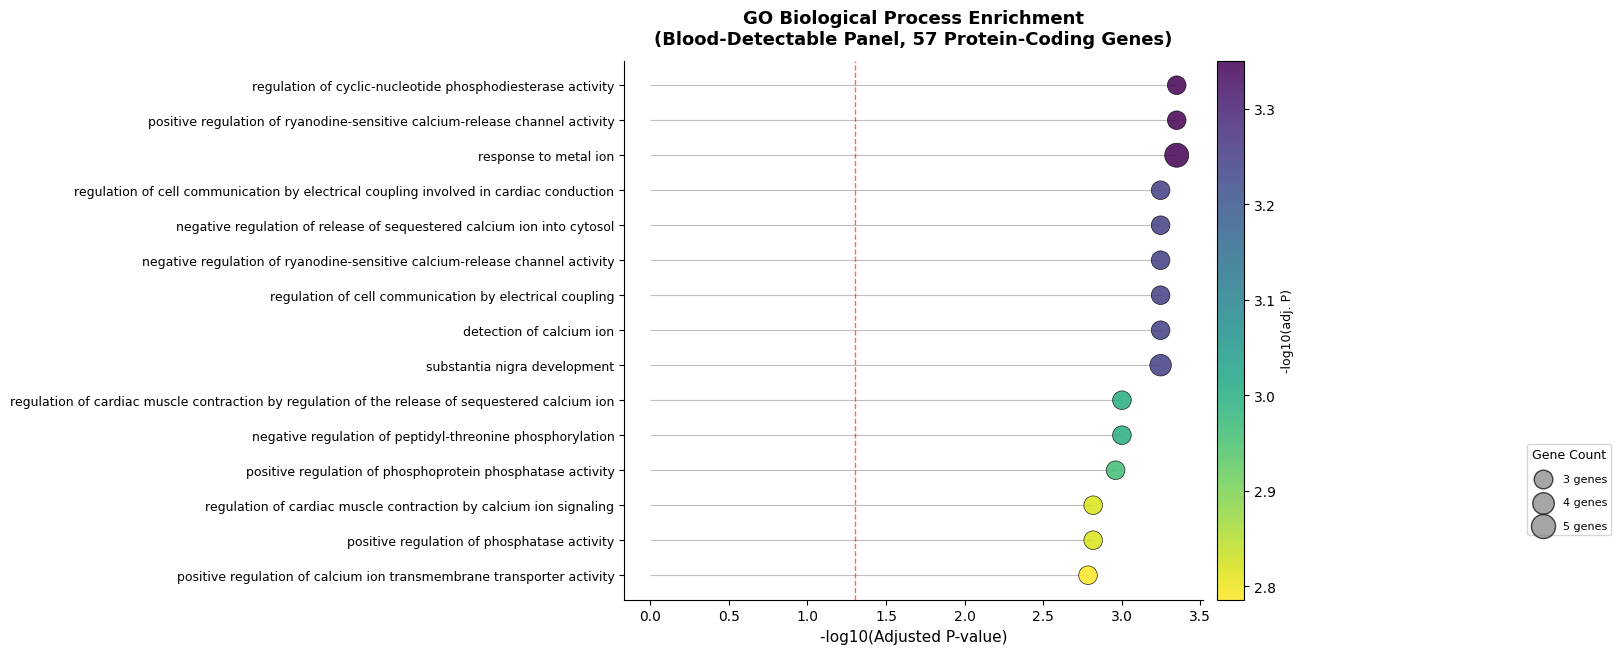

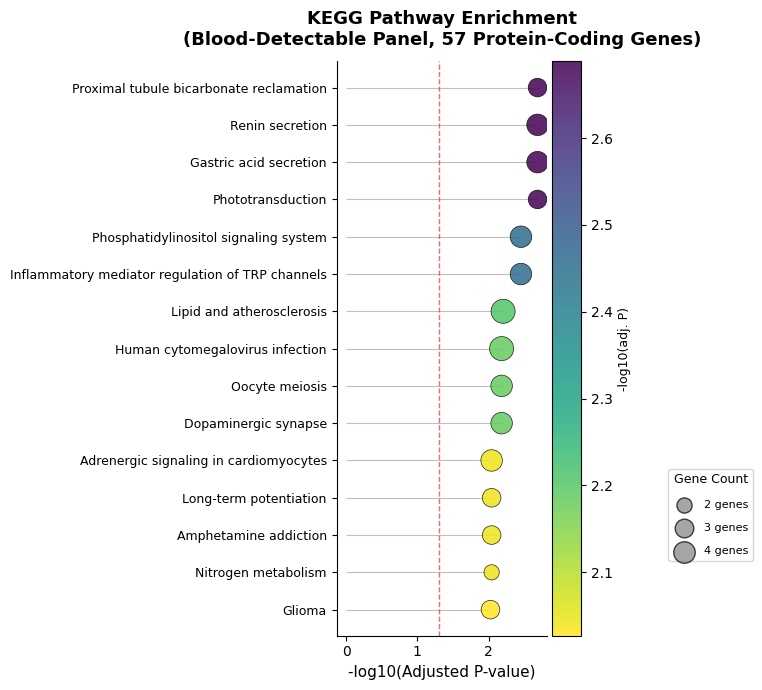


Neutrophil-related GO terms (checked across ALL terms, not just top 15):
                                                               Term Overlap  Adjusted P-value               Genes
523                           neutrophil degranulation (GO:0043312)   3/481          0.226824  CFD;RAB27A;S100A11
526  neutrophil activation involved in immune response (GO:0002283)   3/485          0.229455  CFD;RAB27A;S100A11
528                       neutrophil mediated immunity (GO:0002446)   3/488          0.229620  CFD;RAB27A;S100A11

 Done — Figure9_KEGG_Enrichment.png and Figure10_GO_Enrichment.png saved.


In [22]:

#  GO + KEGG ENRICHMENT


!pip install gseapy -q

import re
import numpy as np
import pandas as pd
import gseapy as gp
import matplotlib.pyplot as plt


# Loaded the blood-detectable panel and keep ONLY protein-coding genes
# (miRNAs, snoRNAs, and annotation artifacts are excluded from enrichment only



blood_genes_raw = pd.read_csv("Validated_Genes_Blood.csv")

all_genes = set()
for entry in blood_genes_raw["Gene_Symbol"].dropna():
    for g in str(entry).split(","):
        g = g.strip()
        if g and g != "N/A":
            all_genes.add(g)

exclude_patterns = [
    r"^MIR\d",     # microRNAs
    r"^SNOR",      # snoRNAs
    r"^SAPCD1$",   # readthrough partner alone
    r"-SAPCD1$",   # fusion/readthrough transcript
    r"^AK\d{6}$",  # GenBank clone/EST IDs
]

def is_excluded(gene):
    return any(re.search(pat, gene) for pat in exclude_patterns)

protein_coding_genes = sorted([g for g in all_genes if not is_excluded(g)])

print(f"Total panel entries: {len(all_genes)}")
print(f"Protein-coding genes used for enrichment: {len(protein_coding_genes)}")
print(protein_coding_genes)


# Running GO Biological enrichment


go_result = gp.enrichr(
    gene_list=protein_coding_genes,
    gene_sets=["GO_Biological_Process_2021"],
    organism="human",
    outdir=None,
    cutoff=0.05
)
go_df = go_result.results.sort_values("Adjusted P-value")
go_df.to_csv("Final_GO_Enrichment.csv", index=False)
go_sig = go_df[go_df["Adjusted P-value"] < 0.05].reset_index(drop=True)
print(f"\nGO significant terms: {len(go_sig)}")


# Running KEGG


kegg_result = gp.enrichr(
    gene_list=protein_coding_genes,
    gene_sets=["KEGG_2021_Human"],
    organism="human",
    outdir=None,
    cutoff=0.05
)
kegg_df = kegg_result.results.sort_values("Adjusted P-value")
kegg_df.to_csv("Final_KEGG_Enrichment.csv", index=False)
kegg_sig = kegg_df[kegg_df["Adjusted P-value"] < 0.05].reset_index(drop=True)
print(f"KEGG significant pathways: {len(kegg_sig)}")



def clean_term_name(term):
    """Strip the trailing (GO:xxxxxxx) or database ID from term labels."""
    return re.sub(r"\s*\(GO:\d+\)", "", term).strip()

def dotplot(df_sig, title, filename, top_n=15, figsize=(9, 7)):
    d = df_sig.head(top_n).copy()
    d["Term_clean"] = d["Term"].apply(clean_term_name)
    d["GeneCount"] = d["Overlap"].apply(lambda x: int(x.split("/")[0]))
    d["neg_log10_p"] = -np.log10(d["Adjusted P-value"])
    d = d.iloc[::-1].reset_index(drop=True)  # most significant at top

    fig, ax = plt.subplots(figsize=figsize)
    scatter = ax.scatter(
        d["neg_log10_p"], d["Term_clean"],
        s=d["GeneCount"] * 60,          # dot size scaled by gene count
        c=d["neg_log10_p"],             # color by significance
        cmap="viridis_r",
        edgecolors="black", linewidths=0.5, alpha=0.85, zorder=3
    )
    ax.hlines(d["Term_clean"], xmin=0, xmax=d["neg_log10_p"], color="grey",
              linewidth=0.8, alpha=0.5, zorder=1)

    ax.set_xlabel("-log10(Adjusted P-value)", fontsize=11)
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.tick_params(axis='y', labelsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    ax.axvline(-np.log10(0.05), color="red", linestyle="--", linewidth=1, alpha=0.6)

    cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
    cbar.set_label("-log10(adj. P)", fontsize=9)

    # legend for dot size (gene count)
    for count in sorted(d["GeneCount"].unique())[:3]:
        ax.scatter([], [], s=count * 60, c="grey", edgecolors="black",
                   alpha=0.7, label=f"{count} genes")
    ax.legend(scatterpoints=1, frameon=True, labelspacing=1.2,
             title="Gene Count", loc="lower right", fontsize=8, title_fontsize=9)
    # ax.legend(scatterpoints=1, frameon=True, labelspacing=1.2,
    #          title="Gene Count", loc="lower left", fontsize=8, title_fontsize=9)
    ax.legend(scatterpoints=1, frameon=True, labelspacing=1.2,
             title="Gene Count", loc="upper left",
             bbox_to_anchor=(1.55, 0.30), fontsize=8, title_fontsize=9)


    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


# Generating two figures


dotplot(go_sig, "GO Biological Process Enrichment\n(Blood-Detectable Panel, 57 Protein-Coding Genes)",
        "Figure10_GO_Enrichment.png")

dotplot(kegg_sig, "KEGG Pathway Enrichment\n(Blood-Detectable Panel, 57 Protein-Coding Genes)",
        "Figure9_KEGG_Enrichment.png")


# Confirming the neutrophil-related finding


neutrophil_terms = go_df[go_df["Term"].str.contains("neutrophil", case=False, na=False)]
print("\nNeutrophil-related GO terms (checked across ALL terms, not just top 15):")
print(neutrophil_terms[["Term", "Overlap", "Adjusted P-value", "Genes"]].to_string())

print("\n Done — Figure9_KEGG_Enrichment.png and Figure10_GO_Enrichment.png saved.")

In [23]:
import pandas as pd
for lab, f in [("GO", "Final_GO_Enrichment.csv"), ("KEGG", "Final_KEGG_Enrichment.csv")]:
    d = pd.read_csv(f)
    d = d[d["Adjusted P-value"] < 0.05].copy()
    d["n"] = d["Overlap"].str.split("/").str[0].astype(int)
    d["only_CALM"] = d["Genes"].apply(
        lambda s: {x.strip() for x in str(s).split(";")} <= {"CALM1", "CALM2", "CALM3"})
    print(f"\n{lab}: {len(d)} significant | <3 genes: {(d.n < 3).sum()} | "
          f"only CALM1/2/3: {d.only_CALM.sum()} | interpretable: {((d.n >= 3) & ~d.only_CALM).sum()}")
    print(d[["Term", "Overlap", "Adjusted P-value", "Genes"]].head(20).to_string(index=False))




GO: 56 significant | <3 genes: 12 | only CALM1/2/3: 40 | interpretable: 8
                                                                                                         Term Overlap  Adjusted P-value                           Genes
                                      regulation of cyclic-nucleotide phosphodiesterase activity (GO:0051342)     3/8          0.000446               CALM3;CALM1;CALM2
                     positive regulation of ryanodine-sensitive calcium-release channel activity (GO:0060316)     3/8          0.000446               CALM3;CALM1;CALM2
                                                                           response to metal ion (GO:0010038)    5/71          0.000446 PPP2CB;NEDD4L;CALM3;CALM1;CALM2
          regulation of cell communication by electrical coupling involved in cardiac conduction (GO:1901844)    3/12          0.000565               CALM3;CALM1;CALM2
                          negative regulation of release of sequestered calcium ion i

In [24]:
import pandas as pd, gseapy as gp
CALM = {"CALM1", "CALM2", "CALM3"}

def independent_genes(s):
    g = {x.strip() for x in str(s).split(";") if x.strip()}
    return len(g - CALM) + (1 if g & CALM else 0)

for lab, f in [("GO", "Final_GO_Enrichment.csv"), ("KEGG", "Final_KEGG_Enrichment.csv")]:
    d = pd.read_csv(f)
    d = d[d["Adjusted P-value"] < 0.05].copy()
    d["indep"] = d["Genes"].apply(independent_genes)
    keep = d[d["indep"] >= 3]
    print(f"\n{lab}: {len(d)} significant | >=3 independent genes (CALM counted once): {len(keep)}")
    print(keep[["Term", "Overlap", "Adjusted P-value", "Genes"]].to_string(index=False))

genes_one = [g for g in protein_coding_genes if g not in ("CALM2", "CALM3")]
for lib, lab in [("GO_Biological_Process_2021", "GO"), ("KEGG_2021_Human", "KEGG")]:
    r = gp.enrichr(gene_list=genes_one, gene_sets=[lib], organism="human",
                   outdir=None, cutoff=0.05).results
    s = r[r["Adjusted P-value"] < 0.05].sort_values("Adjusted P-value")
    print(f"\n{lab} with CALM2/CALM3 removed: {len(s)} significant")
    print(s[["Term", "Overlap", "Adjusted P-value", "Genes"]].head(15).to_string(index=False))


GO: 56 significant | >=3 independent genes (CALM counted once): 6
                                               Term Overlap  Adjusted P-value                                 Genes
                 response to metal ion (GO:0010038)    5/71          0.000446       PPP2CB;NEDD4L;CALM3;CALM1;CALM2
                 bicarbonate transport (GO:0015701)    3/35          0.003910                        CA2;CA4;SLC4A4
           skeletal system development (GO:0001501)   4/158          0.021250              PTGER4;COL1A1;TCOF1;SOX4
     negative regulation of cell cycle (GO:0045786)    3/80          0.028423                  CDK5RAP1;PDCD4;INHBA
positive regulation of gene expression (GO:0010628)   6/482          0.039995 PTGER4;TAF1D;HILPDA;RAB27A;INHBA;SOX4
               organic anion transport (GO:0015711)    3/99          0.044612                        CA2;CA4;SLC4A4

KEGG: 40 significant | >=3 independent genes (CALM counted once): 6
                                   Term Overlap  Adj